# Phase 4 — Compare Context Windows (2 vs. 3)

**Author:** Aboudlal  
**Date:** 2026-10

This notebook explores how changing the context window changes co-occurrence results for the original 22-document corpus. This is the technical modification requested for Project 3.


In [1]:
from collections import Counter, defaultdict

import matplotlib.pyplot as plt

corpus: list[dict[str, str]] = [
    # Dogs
    {"category": "dog", "text": "A dog barks loudly."},
    {"category": "dog", "text": "The puppy runs in the yard."},
    {"category": "dog", "text": "A canine wears a leash."},
    {"category": "dog", "text": "The kennel holds the dog."},
    {"category": "dog", "text": "The dog ran across the yard."},
    {"category": "dog", "text": "The puppy ran across the yard."},
    # Cats
    {"category": "cat", "text": "A cat sleeps quietly."},
    {"category": "cat", "text": "The kitten plays with yarn."},
    {"category": "cat", "text": "A feline purrs softly."},
    {"category": "cat", "text": "The cat has whiskers."},
    {"category": "cat", "text": "The cat slept near the window."},
    {"category": "cat", "text": "The kitten slept near the window."},
    # Cars
    {"category": "car", "text": "A car drives on the road."},
    {"category": "car", "text": "The sedan parks in the garage."},
    {"category": "car", "text": "A vehicle has four wheels."},
    {"category": "car", "text": "The car moves down the highway."},
    {"category": "car", "text": "The car stopped near the garage."},
    {"category": "car", "text": "The sedan stopped near the garage."},
    # Trucks
    {"category": "truck", "text": "A truck carries cargo."},
    {"category": "truck", "text": "The pickup pulls a trailer."},
    {"category": "truck", "text": "The engine powers the truck."},
    {"category": "truck", "text": "The truck hauls heavy loads."},
]


def tokenize(text: str) -> list[str]:
    """Tokenize the input text into a list of cleaned tokens."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


print(f"Corpus contains {len(corpus)} documents.")

Corpus contains 22 documents.


## Compare the original window (2) with the modified window (3)

A context window includes words before and after a target word, but not the target position itself. We keep context inside the same document.


In [2]:
BASELINE_WINDOW_SIZE = 2
WINDOW_SIZE = 3
TARGET_TOKENS = ["dog", "cat", "car", "truck"]


def collect_co_occurrences(window_size: int) -> dict[str, list[str]]:
    """Collect nearby words without crossing document boundaries."""
    contexts: dict[str, list[str]] = defaultdict(list)
    for doc in corpus:
        tokens = tokenize(doc["text"])
        for i, token in enumerate(tokens):
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            for j in range(start, end):
                if j != i:  # Exclude only the target position itself.
                    contexts[token].append(tokens[j])
    return contexts


baseline_contexts = collect_co_occurrences(BASELINE_WINDOW_SIZE)
co_occurrence_dict = collect_co_occurrences(WINDOW_SIZE)

print("\nPHASE 4: CONTEXT WINDOW COMPARISON (2 vs. 3)")
for target in TARGET_TOKENS:
    old_context = baseline_contexts[target]
    new_context = co_occurrence_dict[target]
    new_words = sorted(set(new_context) - set(old_context))
    top_words = Counter(new_context).most_common(5)

    print(f"\nTarget: {target}")
    print(
        f"  Window 2: {len(old_context)} nearby tokens, "
        f"{len(set(old_context))} distinct words"
    )
    print(
        f"  Window 3: {len(new_context)} nearby tokens, "
        f"{len(set(new_context))} distinct words"
    )
    print(f"  New context words with window 3: {new_words}")
    print(f"  Most common context words (window 3): {top_words}")


PHASE 4: CONTEXT WINDOW COMPARISON (2 vs. 3)

Target: dog
  Window 2: 7 nearby tokens, 6 distinct words
  Window 3: 9 nearby tokens, 7 distinct words
  New context words with window 3: ['kennel']
  Most common context words (window 3): [('the', 3), ('barks', 1), ('loudly', 1), ('kennel', 1), ('holds', 1)]

Target: cat
  Window 2: 8 nearby tokens, 7 distinct words
  Window 3: 9 nearby tokens, 7 distinct words
  New context words with window 3: []
  Most common context words (window 3): [('the', 3), ('sleeps', 1), ('quietly', 1), ('has', 1), ('whiskers', 1)]

Target: car
  Window 2: 8 nearby tokens, 6 distinct words
  Window 3: 11 nearby tokens, 7 distinct words
  New context words with window 3: ['road']
  Most common context words (window 3): [('the', 5), ('drives', 1), ('road', 1), ('moves', 1), ('down', 1)]

Target: truck
  Window 2: 7 nearby tokens, 6 distinct words
  Window 3: 9 nearby tokens, 8 distinct words
  New context words with window 3: ['engine', 'loads']
  Most common co

## Visualize the effect

A bigger context window usually includes more nearby token occurrences.


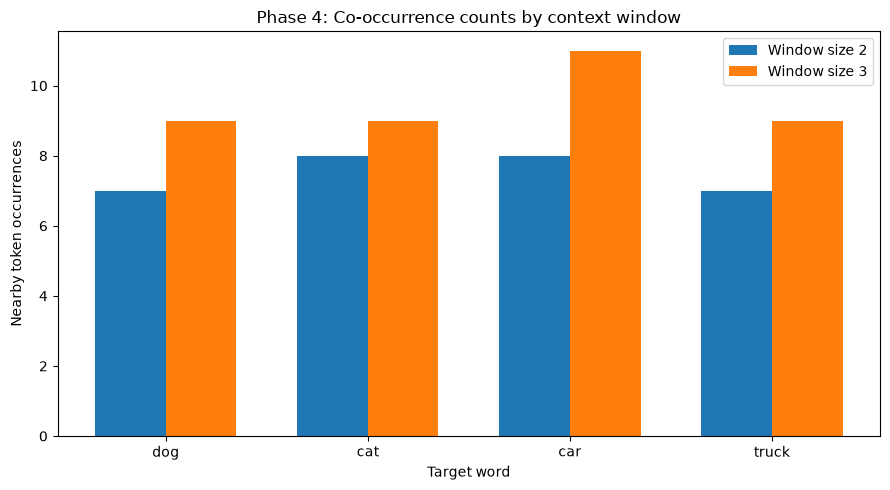

In [3]:
targets = TARGET_TOKENS
counts_2 = [len(baseline_contexts[t]) for t in targets]
counts_3 = [len(co_occurrence_dict[t]) for t in targets]
positions = list(range(len(targets)))
bar_width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    [x - bar_width / 2 for x in positions],
    counts_2,
    width=bar_width,
    label="Window size 2",
)
plt.bar(
    [x + bar_width / 2 for x in positions],
    counts_3,
    width=bar_width,
    label="Window size 3",
)
plt.xticks(positions, targets)
plt.title("Phase 4: Co-occurrence counts by context window")
plt.xlabel("Target word")
plt.ylabel("Nearby token occurrences")
plt.legend()
plt.tight_layout()
plt.show()

## Interpretation

The larger window includes additional nearby words for the selected targets. This helps explore more context but may also introduce less relevant words. Word proximity alone cannot establish semantic similarity. The original document categories and text stay unchanged so that window size is the variable being compared.
